In [2]:
!pip -q install librosa soundfile matplotlib numpy

**1. Import i parametry**

In [3]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

**2. Wczytanie audio**




In [8]:
def wczytaj_audio(sciezka=None):
    """Wczytuje audio do 16 kHz mono. Bez pliku zwraca sygnał syntetyczny."""
    if sciezka:
        try:
            y, sr = librosa.load(sciezka, sr=SR, mono=True)
            return y.astype(np.float32), sr
        except:
            print(f"Nie znaleziono pliku {sciezka}, używam sygnału syntetycznego.")

    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

# Słownik z nagraniami
nagrania = {
    'Samogłoska': 'amogłoska.wav',
    'Wyraz': 'wyraz.wav',
    'Zdanie': 'zdanie.wav'
}

dane = {}
for nazwa, plik in nagrania.items():
    y, sr = wczytaj_audio(plik)
    dane[nazwa] = {'y': y, 'sr': sr}

    # Wypisanie parametrów (zgodnie z ćwiczeniem)
    print(f"--- {nazwa} ---")
    print(f"Liczba próbek: {len(y)}")
    print(f"Częstotliwość próbkowania: {sr} Hz")
    print(f"Czas trwania: {len(y) / sr:.2f} s\n")

--- Samogłoska ---
Liczba próbek: 21209
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 1.33 s

--- Wyraz ---
Liczba próbek: 9660
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 0.60 s

--- Zdanie ---
Liczba próbek: 45579
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.85 s



**3. Odsłuch**

In [9]:
from IPython.display import Audio, display

for nazwa, dane_audio in dane.items():
    print(f"Odsłuch: {nazwa}")
    display(Audio(dane_audio['y'], rate=dane_audio['sr']))

Odsłuch: Samogłoska


Odsłuch: Wyraz


Odsłuch: Zdanie


**4. Reprezentacje: log-mel i MFCC**

In [11]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13, n_fft=N_FFT, hop_length=HOP_LENGTH):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length
    )

# Obliczenie i wypisanie kształtów dla wszystkich nagrań
for nazwa, dane_audio in dane.items():
    y, sr = dane_audio['y'], dane_audio['sr']
    S_db = log_mel(y, sr)
    M = mfcc(y, sr)
    print(f"--- {nazwa} ---")
    print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
    print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)\n")

--- Samogłoska ---
Kształt log-mel: (64, 133)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 133)  (współczynniki × ramki czasowe)

--- Wyraz ---
Kształt log-mel: (64, 61)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 61)  (współczynniki × ramki czasowe)

--- Zdanie ---
Kształt log-mel: (64, 285)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 285)  (współczynniki × ramki czasowe)



**5. Wizualizacja i porównanie trzech nagrań**

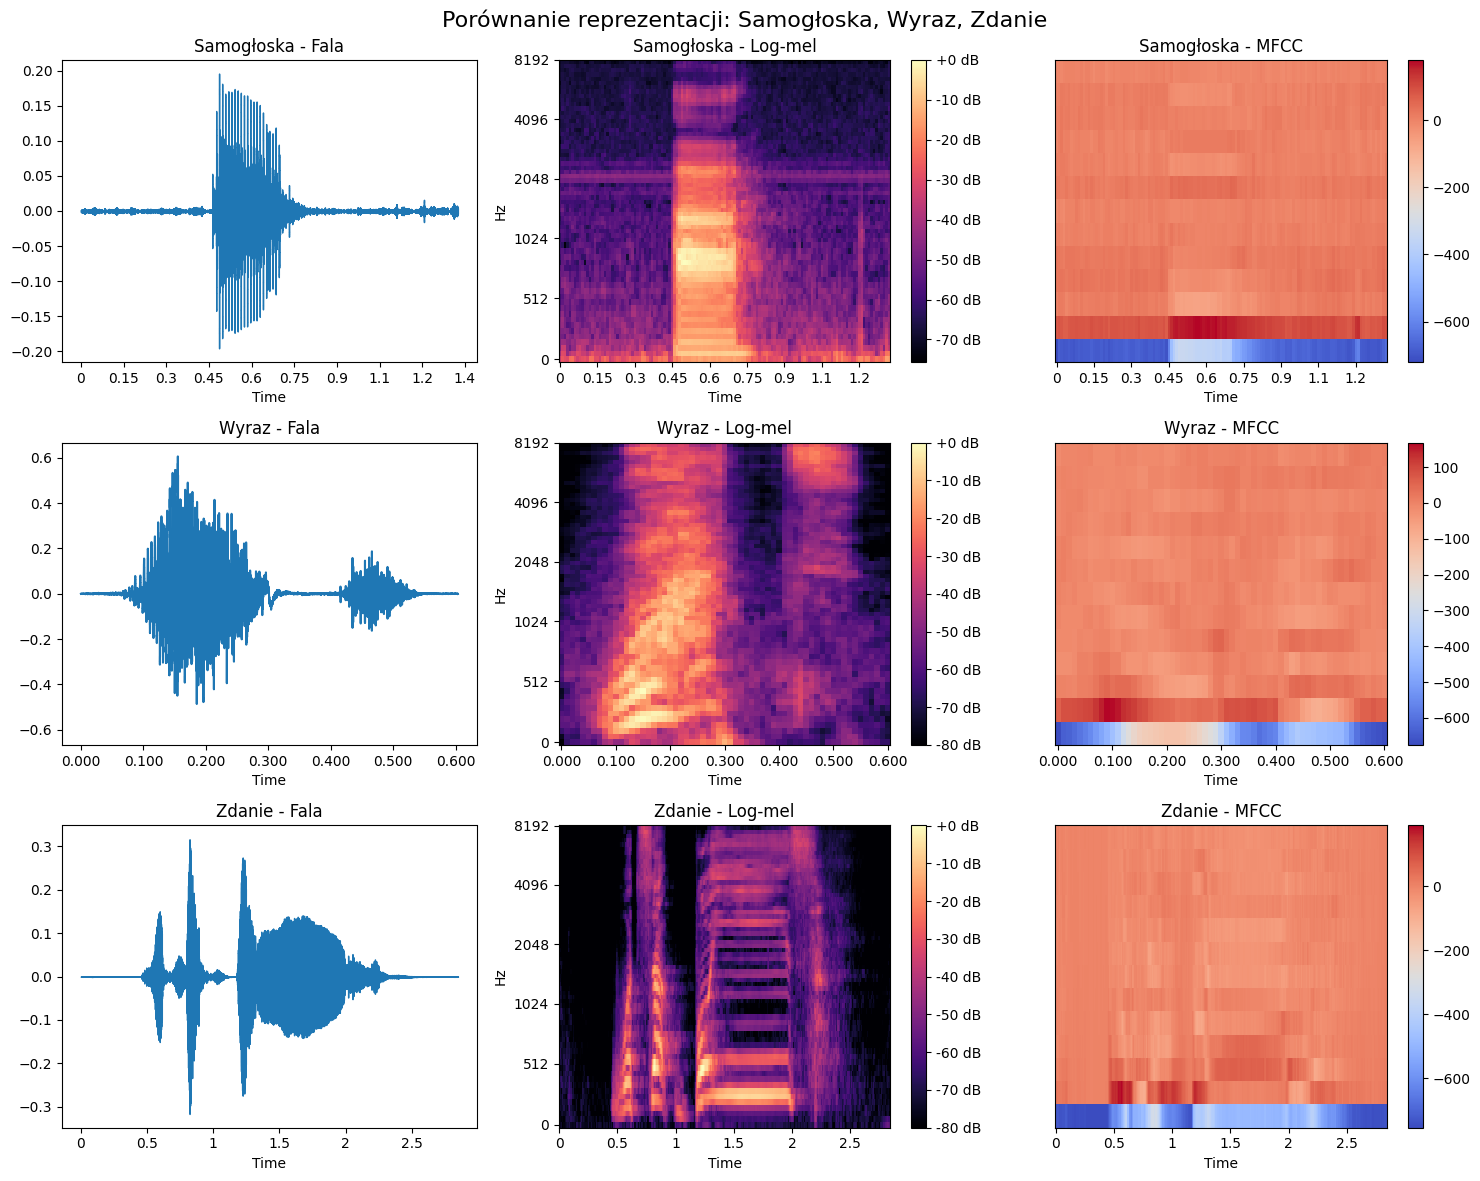

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Porównanie reprezentacji: Samogłoska, Wyraz, Zdanie', fontsize=16)

for i, (nazwa, dane_audio) in enumerate(dane.items()):
    y, sr = dane_audio['y'], dane_audio['sr']
    S_db = log_mel(y, sr)
    M = mfcc(y, sr)

    # Fala
    librosa.display.waveshow(y, sr=sr, ax=axes[i, 0])
    axes[i, 0].set_title(f'{nazwa} - Fala')

    # Log-mel
    img1 = librosa.display.specshow(S_db, sr=sr, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=axes[i, 1])
    axes[i, 1].set_title(f'{nazwa} - Log-mel')
    fig.colorbar(img1, ax=axes[i, 1], format='%+2.0f dB')

    # MFCC
    img2 = librosa.display.specshow(M, sr=sr, hop_length=HOP_LENGTH, x_axis='time', ax=axes[i, 2])
    axes[i, 2].set_title(f'{nazwa} - MFCC')
    fig.colorbar(img2, ax=axes[i, 2])

plt.tight_layout()
plt.show()

**5. Wpływ parametrów `n_fft` i `hop_length`**

Wpływ n_fft

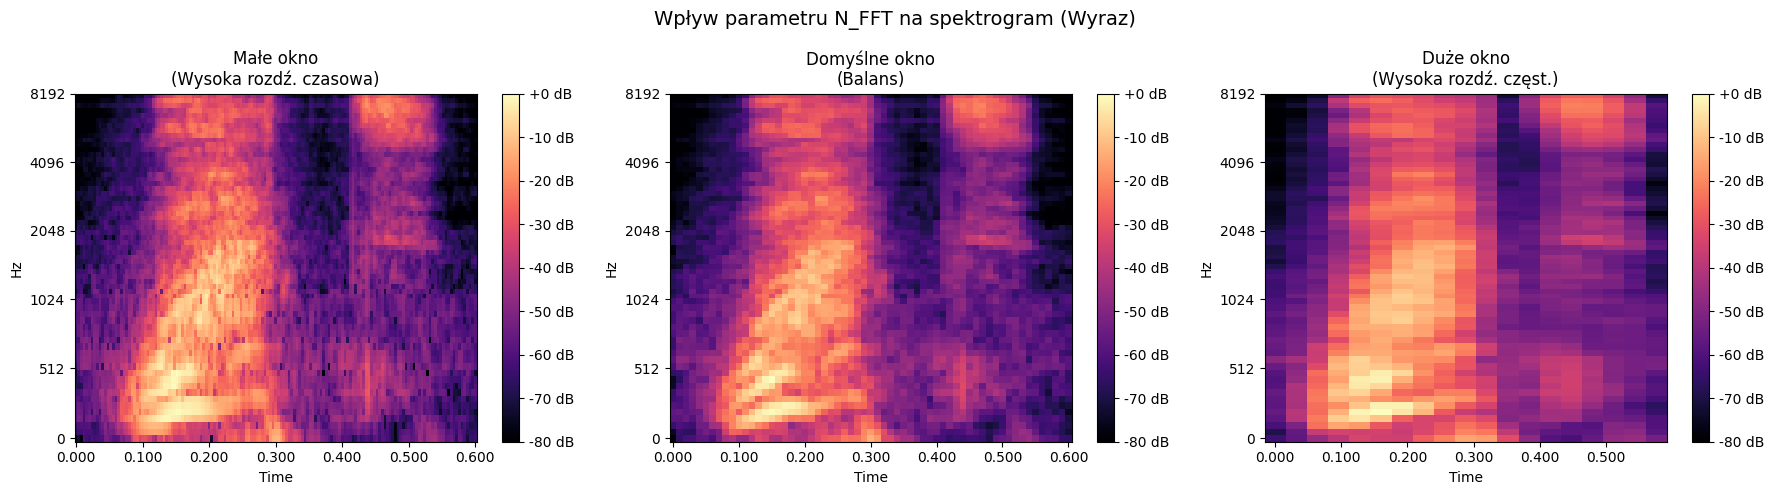

In [13]:
# Wybieramy nagranie "Wyraz" do zbadania wpływu parametrów
y_slowo, sr_slowo = dane['Wyraz']['y'], dane['Wyraz']['sr']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Wpływ parametru N_FFT na spektrogram (Wyraz)', fontsize=14)

parametry = [
    (256, 64, 'Małe okno\n(Wysoka rozdź. czasowa)'),
    (512, 160, 'Domyślne okno\n(Balans)'),
    (2048, 512, 'Duże okno\n(Wysoka rozdź. częst.)')
]

for idx, (n_fft, hop, title) in enumerate(parametry):
    S_db = log_mel(y_slowo, sr_slowo, n_fft=n_fft, hop_length=hop)
    img = librosa.display.specshow(S_db, sr=sr_slowo, hop_length=hop, x_axis='time', y_axis='mel', ax=axes[idx])
    axes[idx].set_title(title)
    fig.colorbar(img, ax=axes[idx], format='%+2.0f dB')

plt.tight_layout()
plt.show()

Wpływ hop_length

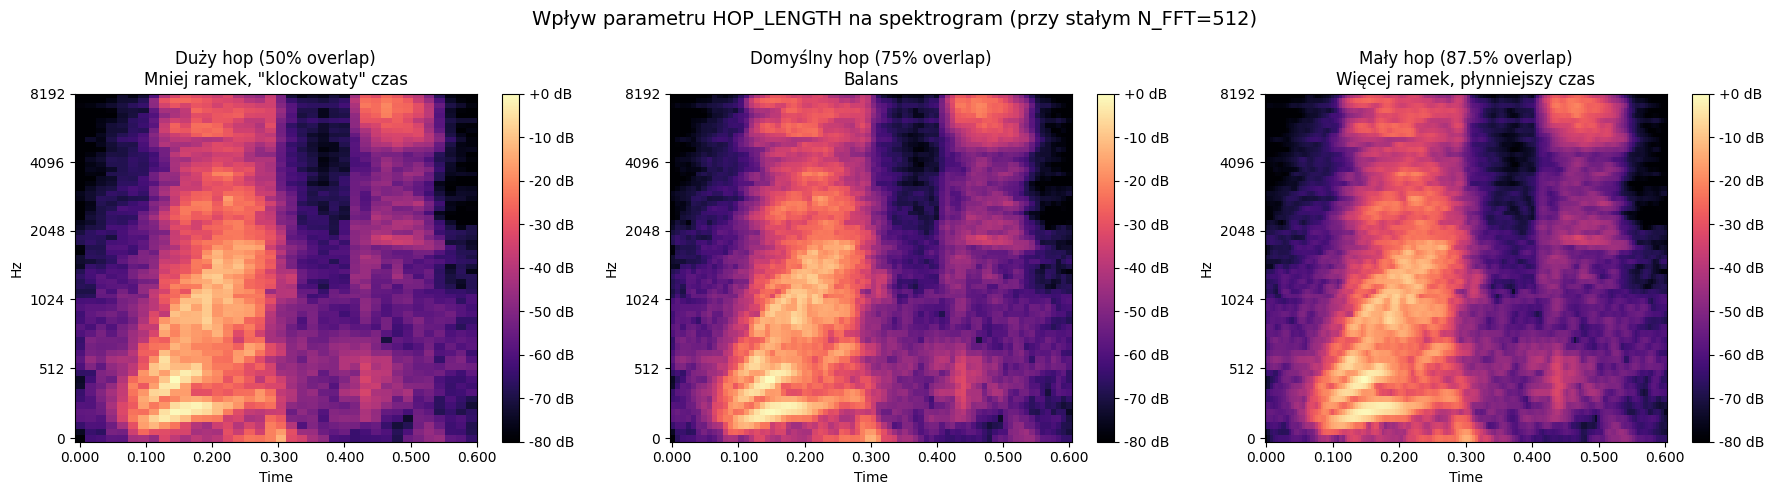

In [14]:
y_slowo, sr_slowo = dane['Wyraz']['y'], dane['Wyraz']['sr']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Wpływ parametru HOP_LENGTH na spektrogram (przy stałym N_FFT=512)', fontsize=14)

parametry_hop = [
    (512, 256, 'Duży hop (50% overlap)\nMniej ramek, "klockowaty" czas'),
    (512, 128, 'Domyślny hop (75% overlap)\nBalans'),
    (512, 64, 'Mały hop (87.5% overlap)\nWięcej ramek, płynniejszy czas')
]

for idx, (n_fft, hop, title) in enumerate(parametry_hop):
    S_db = log_mel(y_slowo, sr_slowo, n_fft=n_fft, hop_length=hop)
    img = librosa.display.specshow(S_db, sr=sr_slowo, hop_length=hop, x_axis='time', y_axis='mel', ax=axes[idx])
    axes[idx].set_title(title)
    fig.colorbar(img, ax=axes[idx], format='%+2.0f dB')

plt.tight_layout()
plt.show()